# 02 · Badminton — segmentacja i ręczna korekta
**Dane rzeczywiste:** cztery serie central/off-center z jednej rakiety, 46 automatycznych kandydatów.
To demonstracja narzędzi, nie pomiar skuteczności wykrywania wad ceramiki.

Wybierz kernel `.venv` / Ping Lab i **Run All**. Ten notebook działa samodzielnie;
nie musisz wcześniej uruchamiać pozostałych. Granice serii i zapowiedzi pochodzą
z `data/raw/badminton/session.json`. `project.json` pozostaje konfiguracją oryginalnych notebooków.
Nowe wyniki trafiają do osobnego katalogu; nagranie źródłowe pozostaje bez zmian.


In [1]:
NOTEBOOK = '02_seria_i_uderzenia'
from pathlib import Path
import sys, json, hashlib, io, base64
from datetime import datetime
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/pinglab').is_dir()), None)
assert ROOT is not None, 'Otwórz notebook z folderu projektu ceramic-ping-lab.'
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT/'scripts'))
%matplotlib inline
cfg = json.loads((ROOT/'data/raw/badminton/session.json').read_text())
SOURCE = ROOT/'data/raw/badminton'/cfg['audio']
assert SOURCE.is_file(), 'Brak nagrania badminton: nie przełączamy się automatycznie na demo.'
OUT = ROOT/'reports/runs/badminton-notebooks'/NOTEBOOK/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf
from scipy.signal import welch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Audio, HTML, Markdown
from pinglab.audio import load_audio, Config
from pinglab.recorder import segment_ringdown, ringdown_plot
from pinglab.features import extract_features, feature_columns, decay_curve
from pinglab.learning import make_classifier
from pinglab.series import evaluate_series, paired_folds
from pinglab.embeddings import ASTEncoder
from pinglab.robustness import mix_noise

RUN_AST = False
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
colors = {'central':'#137f83', 'offcenter':'#c56838'}
r = load_audio(SOURCE, Config(sr=48000, max_seconds=180))
print('Plik:', SOURCE.name, '| SHA256:', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(pd.DataFrame([r.qc]).drop(columns=['warnings']))
print('Uwagi QC:', r.qc['warnings'] or 'brak')

Plik: session.wav | SHA256: afc2d308b32b80ead3f80f795707a2059d2e359a33a2d6c20470464d41df7f07


,duration_s,native_sr,channels,selected_channel,peak_dbfs,rms_dbfs,clipping_fraction,dc_offset
0,88.99771,44100,1,0,-17.976912,-45.595115,0.0,8.182004e-09


Uwagi QC: ['Pasmo źródłowe kończy się przy 22050 Hz; resampling go nie odzyska']


## 1. Cztery serie, bez zapowiedzi w danych modelu
Pierwsza etykieta pochodzi z opisu nagrania. Trzy kolejne zapowiedzi potwierdzono lokalną transkrypcją: „uderzenia niecentralne, off center”, „druga seria uderzeń centralnych”, „druga seria uderzeń off center”.
Granice poniżej ustalono na przebiegu, przed modelowaniem. Odsłuchaj serie, jeśli chcesz sprawdzić trafienia.


,series_id,label,round,start_s,end_s
0,central_1,central,1,6.5,24.5
1,offcenter_1,offcenter,1,32.0,46.5
2,central_2,central,2,56.0,69.0
3,offcenter_2,offcenter,2,75.5,88.0


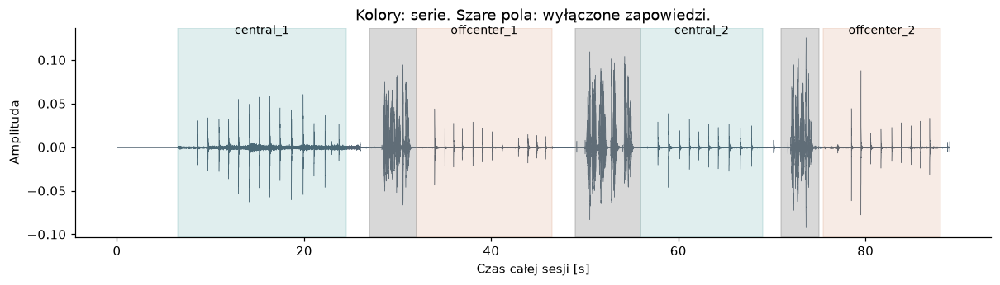

**central_1**

**offcenter_1**

**central_2**

**offcenter_2**

In [2]:
series = pd.DataFrame(cfg['series'])
display(series)
fig, ax = plt.subplots(figsize=(13,3))
step=max(1,len(r.y)//12000)
blocks=r.y[:len(r.y)//step*step].reshape(-1,step)
t=np.arange(len(blocks))*step/r.sr
ax.fill_between(t,blocks.min(1),blocks.max(1),color='#536574',lw=.3)
for s in cfg['series']:
 ax.axvspan(s['start_s'],s['end_s'],alpha=.13,color=colors[s['label']])
 ax.text((s['start_s']+s['end_s'])/2,.13,s['series_id'],ha='center',fontsize=9)
for a,b in cfg['speech_excluded_s']: ax.axvspan(a,b,color='grey',alpha=.3)
ax.set(xlabel='Czas całej sesji [s]',ylabel='Amplituda',title='Kolory: serie. Szare pola: wyłączone zapowiedzi.')
plt.show()
for s in cfg['series']:
 a,b=int(s['start_s']*r.sr),int(s['end_s']*r.sr)
 display(Markdown('**'+s['series_id']+'**'))
 display(Audio(r.y[a:b],rate=r.sr,normalize=False))
 sf.write(OUT/(s['series_id']+'.wav'),r.y[a:b],r.sr,subtype='PCM_24')

## Korekta detekcji
Sekundy liczymy od początku wybranej serii, nie całego nagrania. Brak klucza = automat. Lista `[]` = odrzucenie wszystkich wykryć tej serii. Korekty dotyczą tego uruchomienia; zapisujemy je w jego wynikach. Pozostałe notebooki nadal używają automatu, dopóki jawnie nie przeniesiemy korekt.

In [3]:
CORRECTIONS = {}  # np. {'central_1': [2.025,3.17,...]} — wpisz pełną listę rzeczywistych początków
known={s['series_id']:s for s in cfg['series']}
assert set(CORRECTIONS) <= set(known)
for sid,seconds in CORRECTIONS.items():
 assert all(np.isfinite(v) and 0<=v<known[sid]['end_s']-known[sid]['start_s'] for v in seconds)
 assert all(a<b for a,b in zip(seconds,seconds[1:])), 'Czasy muszą rosnąć.'
(OUT/'corrections.json').write_text(json.dumps(CORRECTIONS,indent=2))


2

## 2. Uderzenie i wybrzmienie
Detektor szuka nagłych zmian widma wyłącznie wewnątrz serii. Nie wymuszamy dziesięciu wykryć.
Czerwony pas to umowne pierwsze 30 ms, zielony — obserwowany spadek do progu tła, pomarańczowy — brak takiego spadku przed następnym zdarzeniem. **To heurystyka, nie pomiar fizycznego czasu tłumienia.** Zmiana tła również może dać pomarańczową flagę.

Model dostaje jednakowe okno: 25 ms przed początkiem + 350 ms po nim, skrócone przed kolejnym uderzeniem. Nie uczymy modelu na długości ręcznie wyciętego klipu.


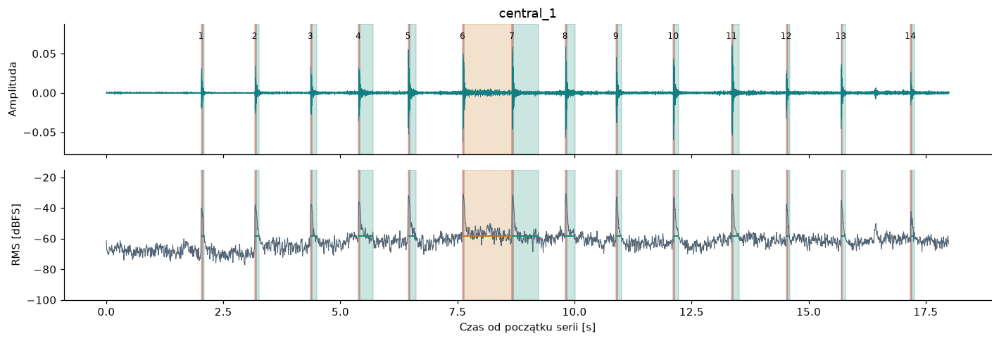

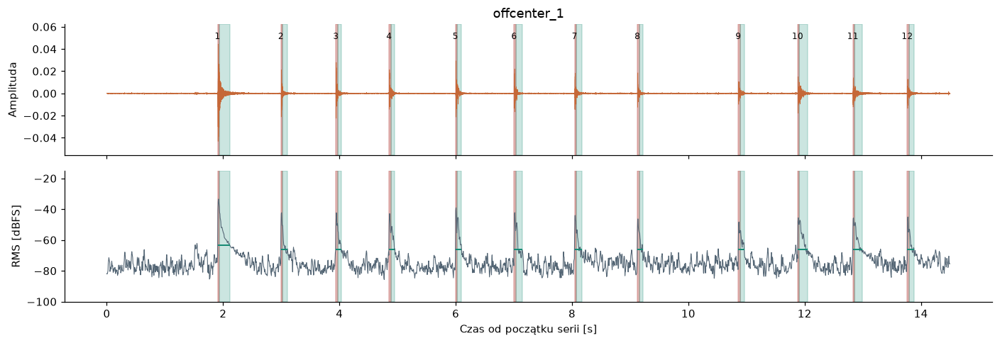

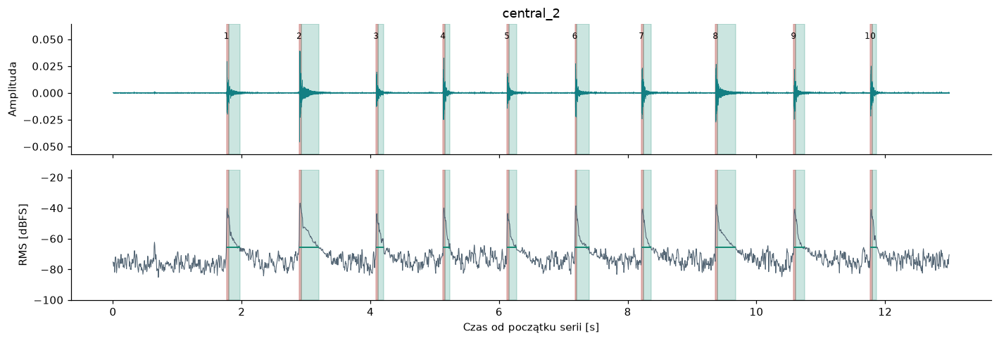

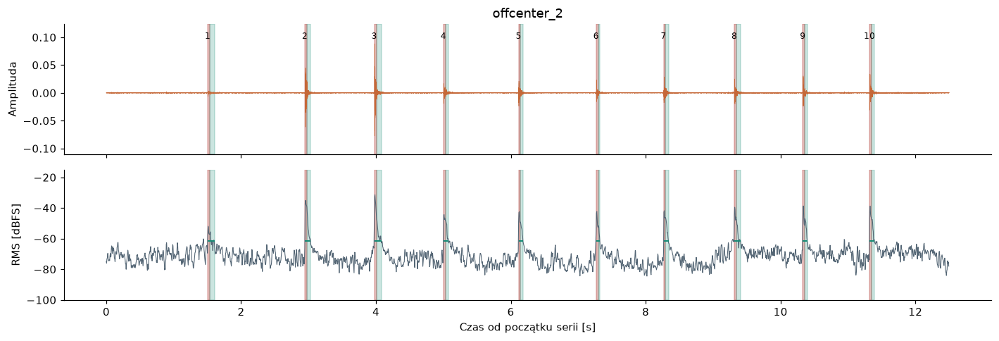

,,uderzenia,szczyt_mediana_dbfs,niepewne
series_id,label,,,
central_1,central,14,-26.799461,0
offcenter_1,offcenter,12,-34.025085,0
central_2,central,10,-31.644835,0
offcenter_2,offcenter,10,-31.444176,1


,event_id,onset_s,ringdown_s,ringdown_status,uncertain
0,central_1_01,8.525,0.070,zanik zaobserwowany,False
1,central_1_02,9.670,0.100,zanik zaobserwowany,False
2,central_1_03,10.860,0.140,zanik zaobserwowany,False
3,central_1_04,11.885,0.315,zanik zaobserwowany,False
4,central_1_05,12.945,0.170,zanik zaobserwowany,False
5,central_1_06,14.110,1.055,kolejne uderzenie przed zanikiem,False
6,central_1_07,15.165,0.570,zanik zaobserwowany,False
7,central_1_08,16.300,0.215,zanik zaobserwowany,False
8,central_1_09,17.385,0.120,zanik zaobserwowany,False
9,central_1_10,18.610,0.115,zanik zaobserwowany,False


In [4]:
rows=[]; clips={}; series_traces={}
for s in cfg['series']:
 z=r.y[int(s['start_s']*r.sr):int(s['end_s']*r.sr)]
 tab,t,db=segment_ringdown(z,r.sr,CORRECTIONS.get(s['series_id']),**cfg['detector'])
 series_traces[s['series_id']]=(z,tab,t,db)
 interactive=ringdown_plot(z,r.sr,tab,t,db)
 interactive.write_html(OUT/(s['series_id']+'_segmentacja.html'),include_plotlyjs=True)
 fig,axes=plt.subplots(2,1,figsize=(13,4.5),sharex=True)
 axes[0].plot(np.arange(len(z))/r.sr,z,lw=.4,color=colors[s['label']])
 axes[1].plot(t,db,lw=.7,color='#536574')
 for k,row in enumerate(tab.itertuples()):
  onset=float(row.onset_s);absolute=s['start_s']+onset
  a=max(0,onset-cfg['pre_s'])
  nxt=float(tab.iloc[k+1].onset_s) if k+1<len(tab) else len(z)/r.sr
  b=min(onset+cfg['feature_tail_s'],nxt-.015,len(z)/r.sr)
  clip=z[int(a*r.sr):int(b*r.sr)]
  eid=f"{s['series_id']}_{k+1:02d}"
  clips[eid]=clip
  uncertain=any(abs(absolute-v)<.05 for v in cfg['uncertain_onsets_s'])
  rows.append(dict(event_id=eid,series_id=s['series_id'],round=s['round'],label=s['label'],
   onset_s=absolute,offset_s=onset-a,window_s=len(clip)/r.sr,
   ringdown_s=row.duration_s,ringdown_status=row.status,uncertain=uncertain,
   peak_dbfs=20*np.log10(max(abs(clip).max(),1e-12)),
   **extract_features(clip,r.sr,onset-a,cfg['fmax'])))
  shade='#c47817' if 'przed zanikiem' in row.status else '#168b75'
  for ax in axes:
   ax.axvspan(onset,row.attack_end_s,color='#b4423e',alpha=.35)
   ax.axvspan(row.attack_end_s,row.end_s,color=shade,alpha=.22)
  axes[0].text(onset,abs(z).max()*1.1,str(k+1),fontsize=8,ha='center')
  axes[1].hlines(row.threshold_dbfs,onset,row.end_s,color=shade,lw=1.3)
 axes[0].set(title=s['series_id'],ylabel='Amplituda',ylim=(-abs(z).max()*1.25,abs(z).max()*1.4))
 axes[1].set(xlabel='Czas od początku serii [s]',ylabel='RMS [dBFS]',ylim=(-100,-15))
 plt.tight_layout();plt.show()
events=pd.DataFrame(rows)
events.to_csv(OUT/'features.csv',index=False)
display(events.groupby(['series_id','label'],sort=False).agg(uderzenia=('event_id','size'),
 szczyt_mediana_dbfs=('peak_dbfs','median'),niepewne=('uncertain','sum')))
display(events[['event_id','onset_s','ringdown_s','ringdown_status','uncertain']])
assert all(not (a<=v<=b) for v in events.onset_s for a,b in cfg['speech_excluded_s'])
assert events.window_s.min()>.05

## Przybliż wybraną serię
Na wykresie możesz zaznaczyć prostokąt, aby przybliżyć fragment. Dwuklik resetuje widok.

In [5]:
SERIES_ID = 'central_1'
z,tab,t,db = series_traces[SERIES_ID]
ringdown_plot(z,r.sr,tab,t,db).show(renderer='plotly_mimetype')


In [6]:
print('GOTOWE:', NOTEBOOK, '| pliki wynikowe:', OUT)

GOTOWE: 02_seria_i_uderzenia | pliki wynikowe: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/badminton-notebooks/02_seria_i_uderzenia/20260928_144903_926180
